# Vector Quantised Variational Autoencoder (VQ-VAE)

Implementation based on: *Neural Discrete Representation Learning* (van den Oord et al., 2017)

**Dataset:** Cats and Dogs — https://www.kaggle.com/datasets/tongpython/cat-and-dog

## Key idea
Unlike a regular VAE that learns a continuous latent distribution, VQ-VAE learns a **discrete codebook** of embeddings. The encoder maps an image to a spatial grid of vectors; each vector is then replaced (quantised) by its nearest codebook entry. The decoder reconstructs from those discrete codes.

**Loss terms:**
- **Reconstruction loss** — MSE between input and output, normalised by training data variance  
- **Commitment loss** — pushes the encoder to commit to its nearest code (weighted by β)  
  *(No separate codebook loss — the codebook is updated via EMA, not gradient descent)*

## Architecture improvements over baseline
| Component | Change | Why |
|-----------|--------|-----|
| Codebook updates | **EMA** (Exponential Moving Average) instead of gradient descent | More stable; prevents codebook collapse |
| Encoder | 3 strided convs + **2 residual blocks** | Richer features → better quantisation |
| Decoder | 2 residual blocks + 3 transposed convs | Better reconstruction quality |
| Perplexity | Tracked as metric (max = K = `NUM_EMBEDDINGS`) | Measures how evenly all codes are used |

In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from keras.preprocessing import image

print(f"TensorFlow: {tf.__version__}")
print(f"GPU available: {len(tf.config.list_physical_devices('GPU')) > 0}")

TensorFlow: 2.20.0
GPU available: False


## Load Dataset (Cats + Dogs)

In [2]:
cat_train_path = "../cats_and_dogs/training_set/training_set/cats/"
cat_test_path  = "../cats_and_dogs/test_set/test_set/cats/"

def load_images(folder, target_size=(128, 128)):
    imgs = []
    for filename in sorted(os.listdir(folder)):
        if filename.lower().endswith(".jpg"):
            img = image.load_img(folder + filename, target_size=target_size)
            imgs.append(image.img_to_array(img))
    return np.array(imgs)

cat_train = load_images(cat_train_path)
cat_test  = load_images(cat_test_path)

print("cat_train:", cat_train.shape)
print("cat_test: ", cat_test.shape)

cat_train: (4000, 128, 128, 3)
cat_test:  (1011, 128, 128, 3)


In [3]:
dog_train_path = "../cats_and_dogs/training_set/training_set/dogs/"
dog_test_path  = "../cats_and_dogs/test_set/test_set/dogs/"

dog_train = load_images(dog_train_path)
dog_test  = load_images(dog_test_path)

print("dog_train:", dog_train.shape)
print("dog_test: ", dog_test.shape)

dog_train: (4005, 128, 128, 3)
dog_test:  (1012, 128, 128, 3)


In [4]:
# Combine cats and dogs, normalise to [0, 1]
x_train_full = np.concatenate([cat_train, dog_train], axis=0).astype("float32") / 255.0
x_test       = np.concatenate([cat_test,  dog_test],  axis=0).astype("float32") / 255.0

# 90/10 split of the training pool — x_test is never touched during training
np.random.seed(42)
perm       = np.random.permutation(len(x_train_full))
val_size   = int(0.10 * len(x_train_full))
val_idx    = perm[:val_size]
train_idx  = perm[val_size:]

x_train = x_train_full[train_idx]
x_val   = x_train_full[val_idx]

print("x_train:", x_train.shape)
print("x_val:  ", x_val.shape,   " ← 10% held out from training pool for validation")
print("x_test: ", x_test.shape,  " ← completely separate, never seen during training")

x_train: (7205, 128, 128, 3)
x_val:   (800, 128, 128, 3)  ← 10% held out from training pool for validation
x_test:  (2023, 128, 128, 3)  ← completely separate, never seen during training


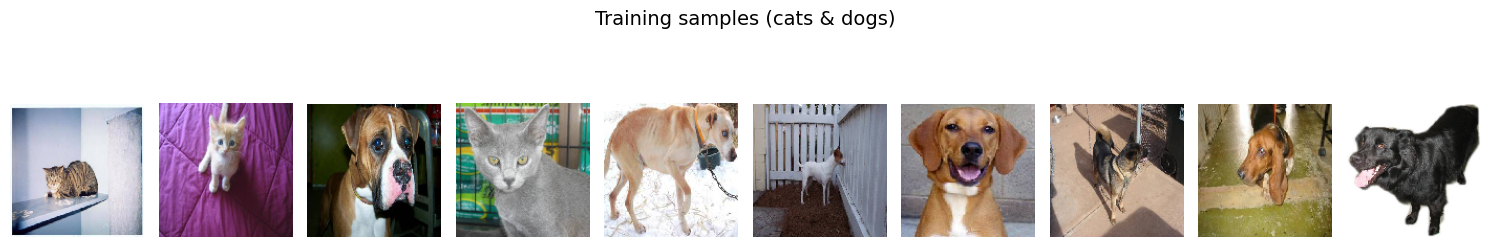

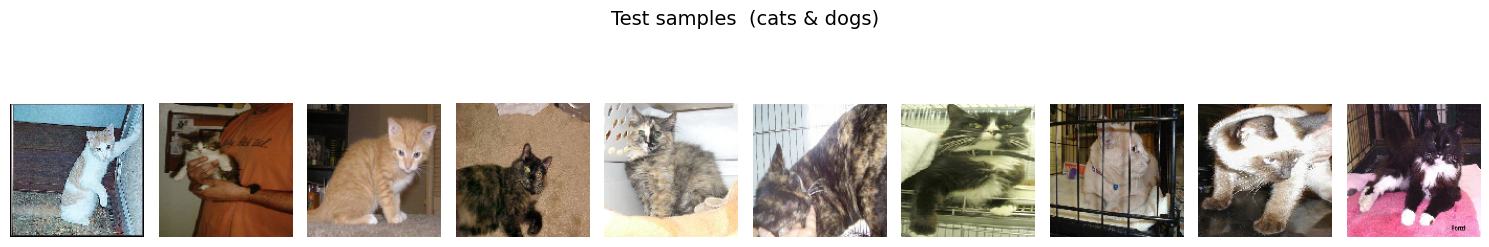

In [5]:
def show_images(images, n=10, title=""):
    plt.figure(figsize=(15, 3))
    for i in range(min(n, len(images))):
        ax = plt.subplot(1, n, i + 1)
        plt.imshow(np.clip(images[i], 0, 1))
        ax.axis("off")
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

show_images(x_train[:10], n=10, title="Training samples (cats & dogs)")
show_images(x_test[:10],  n=10, title="Test samples  (cats & dogs)")

## VQ-VAE Architecture

```
Image (128×128×3)
    ↓  Encoder (3× stride-2 conv)
z_e  (16×16×D)        ← continuous encoder output
    ↓  Vector Quantizer
z_q  (16×16×D)        ← nearest codebook entries (straight-through grad)
    ↓  Decoder (3× stride-2 transposed conv)
x̂   (128×128×3)       ← reconstruction
```

**Hyperparameters**
| Parameter | Value | Description |
|-----------|-------|-------------|
| `embedding_dim` D | 64 | dimension of each codebook vector |
| `num_embeddings` K | 128 | number of discrete codes in codebook |
| β (`beta`) | 0.25 | commitment loss weight (from original paper) |

In [6]:
IMAGE_SIZE     = 128
EMBEDDING_DIM  = 64    # D: dimension of each codebook vector
NUM_EMBEDDINGS = 128   # K: number of discrete codes
BETA           = 0.25  # commitment loss weight (from original paper)
EMA_DECAY      = 0.99  # γ: EMA decay rate for codebook updates
EMA_EPSILON    = 1e-5  # Laplace smoothing — keeps cluster sizes positive

LATENT_H = IMAGE_SIZE // 8   # 16  (3 stride-2 layers → 128/2/2/2)
LATENT_W = IMAGE_SIZE // 8   # 16

In [7]:
class VectorQuantizerEMA(layers.Layer):
    """
    VQ layer with Exponential Moving Average (EMA) codebook updates.

    Instead of learning the codebook via gradient descent (which causes instability
    and codebook collapse), the codebook entries are updated each step as EMA of
    the encoder outputs assigned to them. This is the method described in Appendix A
    of van den Oord et al. (2017) and leads to much higher codebook utilisation.

    Key differences from gradient-based VQ:
      - embeddings is trainable=False  (EMA handles it, not backprop)
      - Only commitment loss is added  (no codebook loss term needed)
      - EMA updates happen as assign() side-effects in call() during training
    """

    def __init__(self, num_embeddings, embedding_dim, beta=0.25,
                 decay=0.99, epsilon=1e-5, **kwargs):
        super().__init__(**kwargs)
        self.num_embeddings = num_embeddings
        self.embedding_dim  = embedding_dim
        self.beta           = beta
        self.decay          = decay    # γ: exponential decay rate
        self.epsilon        = epsilon  # for Laplace smoothing

    def build(self, input_shape):
        # Codebook — NOT trained by backprop; updated by EMA assigns in call()
        self.embeddings = self.add_weight(
            shape=(self.embedding_dim, self.num_embeddings),
            initializer="random_normal",
            trainable=False,
            name="embeddings_vqvae",
        )
        # EMA running count: N_i = how many encoder outputs map to code i
        self.ema_cluster_size = self.add_weight(
            shape=(self.num_embeddings,),
            initializer="ones",   # start at 1 to avoid div-by-zero at step 0
            trainable=False,
            name="ema_cluster_size",
        )
        # EMA running sum: m_i = sum of encoder outputs that mapped to code i
        self.ema_dw = self.add_weight(
            shape=(self.embedding_dim, self.num_embeddings),
            initializer="zeros",
            trainable=False,
            name="ema_dw",
        )
        # Initialise ema_dw to match the starting codebook so first update is sane
        self.ema_dw.assign(self.embeddings)
        super().build(input_shape)

    def call(self, x, training=None):
        # x: (batch, H, W, D)
        input_shape = tf.shape(x)
        flattened   = tf.reshape(x, [-1, self.embedding_dim])  # (N, D)  N=batch*H*W

        # Nearest-neighbour lookup: ||z_e - e||^2 = ||z_e||^2 + ||e||^2 - 2*(z_e·e)
        distances = (
            tf.reduce_sum(flattened ** 2, axis=1, keepdims=True)
            + tf.reduce_sum(self.embeddings ** 2, axis=0, keepdims=True)
            - 2.0 * tf.matmul(flattened, self.embeddings)
        )
        encoding_indices = tf.argmin(distances, axis=1)                        # (N,)
        encoding_indices_spatial = tf.reshape(encoding_indices, input_shape[:-1])  # (B, H, W)

        encodings = tf.one_hot(encoding_indices, self.num_embeddings)          # (N, K)
        quantized = tf.matmul(encodings, tf.transpose(self.embeddings))        # (N, D)
        quantized = tf.reshape(quantized, input_shape)                         # (B, H, W, D)

        if training:
            # --- EMA codebook update (Appendix A, van den Oord et al. 2017) ---

            # Count how many encoder outputs were assigned to each code this batch
            batch_cluster_size = tf.reduce_sum(encodings, axis=0)             # (K,)
            updated_ema_cluster_size = (
                self.ema_cluster_size * self.decay
                + batch_cluster_size  * (1.0 - self.decay)
            )

            # Sum the encoder outputs that mapped to each code
            dw = tf.matmul(tf.transpose(flattened), encodings)               # (D, K)
            updated_ema_dw = (
                self.ema_dw * self.decay
                + dw        * (1.0 - self.decay)
            )

            # Laplace smoothing: keeps all cluster sizes positive while
            # preserving their total sum (prevents division by zero for dead codes)
            n = tf.reduce_sum(updated_ema_cluster_size)
            smoothed_cluster_size = (
                (updated_ema_cluster_size + self.epsilon)
                / (n + self.num_embeddings * self.epsilon)
                * n
            )

            # Update codebook: e_i = m_i / N_i
            new_embeddings = updated_ema_dw / tf.reshape(smoothed_cluster_size, [1, -1])

            self.ema_cluster_size.assign(updated_ema_cluster_size)
            self.ema_dw.assign(updated_ema_dw)
            self.embeddings.assign(new_embeddings)

        # Only commitment loss — the codebook is not updated via gradient with EMA
        commitment_loss = tf.reduce_mean((tf.stop_gradient(quantized) - x) ** 2)
        self.add_loss(self.beta * commitment_loss)

        # Straight-through estimator: decoder gradients pass through to encoder unchanged
        quantized = x + tf.stop_gradient(quantized - x)

        return quantized, encoding_indices_spatial

    def get_code_indices(self, x):
        """Nearest-codebook lookup without adding any loss (inference only)."""
        flattened = tf.reshape(x, [-1, self.embedding_dim])
        distances = (
            tf.reduce_sum(flattened ** 2, axis=1, keepdims=True)
            + tf.reduce_sum(self.embeddings ** 2, axis=0, keepdims=True)
            - 2.0 * tf.matmul(flattened, self.embeddings)
        )
        return tf.argmin(distances, axis=1)


# ---------------------------------------------------------------------------
# Metric helpers used in VQVAETrainer
# ---------------------------------------------------------------------------

def compute_perplexity(encoding_indices, num_embeddings):
    """
    Perplexity = exp(H), where H = -Σ p_i * log(p_i) is the Shannon entropy
    of the code-usage distribution.

      perplexity = 1            → only 1 code ever used (complete collapse)
      perplexity = num_embeddings → all codes used equally (ideal)

    Tracking this over epochs shows how quickly the codebook saturates.
    """
    flat             = tf.cast(tf.reshape(encoding_indices, [-1]), tf.int32)
    encodings_onehot = tf.one_hot(flat, num_embeddings)          # (N, K)
    avg_probs        = tf.reduce_mean(encodings_onehot, axis=0)  # (K,) = p_i per code
    perplexity       = tf.exp(-tf.reduce_sum(avg_probs * tf.math.log(avg_probs + 1e-10)))
    return perplexity


def codebook_usage(encoding_indices, num_embeddings):
    """Count distinct codebook entries used in this batch (scalar float)."""
    flat         = tf.reshape(encoding_indices, [-1])
    unique_codes = tf.unique(flat).y
    return tf.cast(tf.size(unique_codes), tf.float32)

In [8]:
def residual_block(x, filters):
    """Identity-shortcut residual block with BatchNorm."""
    residual = x
    x = layers.Conv2D(filters, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(filters, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Add()([x, residual])
    x = layers.Activation("relu")(x)
    return x


def build_encoder(image_size=128, embedding_dim=64):
    """
    3× stride-2 conv: 128 → 64 → 32 → 16 (×128 channels)
    then 2 residual blocks at the bottleneck (richer features before quantisation)
    then 1×1 conv to project to embedding_dim.
    """
    inputs = keras.Input(shape=(image_size, image_size, 3), name="encoder_input")
    x = layers.Conv2D(64,  3, strides=2, padding="same", activation="relu")(inputs)  # 64×64
    x = layers.Conv2D(128, 3, strides=2, padding="same", activation="relu")(x)        # 32×32
    x = layers.Conv2D(128, 3, strides=2, padding="same", activation="relu")(x)        # 16×16
    x = residual_block(x, 128)
    x = residual_block(x, 128)
    outputs = layers.Conv2D(embedding_dim, 1, padding="same", name="z_e")(x)          # 16×16×D
    return keras.Model(inputs, outputs, name="encoder")


def build_decoder(latent_shape, embedding_dim=64):
    """
    1×1 conv to expand channels, 2 residual blocks,
    then 3× stride-2 transposed conv: 16 → 32 → 64 → 128,
    then 1×1 conv to RGB.
    """
    inputs = keras.Input(shape=latent_shape, name="decoder_input")
    x = layers.Conv2D(128, 1, padding="same")(inputs)              # expand to 128 channels
    x = residual_block(x, 128)
    x = residual_block(x, 128)
    x = layers.Conv2DTranspose(128, 3, strides=2, padding="same", activation="relu")(x)  # 32×32
    x = layers.Conv2DTranspose(64,  3, strides=2, padding="same", activation="relu")(x)  # 64×64
    x = layers.Conv2DTranspose(32,  3, strides=2, padding="same", activation="relu")(x)  # 128×128
    outputs = layers.Conv2D(3, 1, padding="same", activation="sigmoid", name="x_recon")(x)
    return keras.Model(inputs, outputs, name="decoder")


encoder = build_encoder(IMAGE_SIZE, EMBEDDING_DIM)
decoder = build_decoder((LATENT_H, LATENT_W, EMBEDDING_DIM), EMBEDDING_DIM)

encoder.summary()
decoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │      1,792 │ encoder_input[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 32, 32,    │     73,856 │ conv2d[0][0]      │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 16, 16,    │    147,584 │ conv2d_1[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 16, 16,    │    147,584 │ conv2d_2[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 16, 16,    │        512 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 16, 16,    │    147,584 │ activation[0][0]  │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        512 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 16, 16,    │          0 │ batch_normalizat… │
│                     │ 128)              │            │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 16, 16,    │          0 │ add[0][0]         │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 16, 16,    │    147,584 │ activation_1[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        512 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │    147,584 │ activation_2[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        512 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 16, 16,    │          0 │ batch_normalizat

 Total params: 823,872 (3.14 MB)

 Trainable params: 822,848 (3.14 MB)

 Non-trainable params: 1,024 (4.00 KB)

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ decoder_input       │ (None, 16, 16,    │          0 │ -                 │
│ (InputLayer)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │      8,320 │ decoder_input[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 16, 16,    │    147,584 │ conv2d_7[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        512 │ conv2d_8[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 16, 16,    │    147,584 │ activation_4[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        512 │ conv2d_9[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 16, 16,    │          0 │ batch_normalizat… │
│                     │ 128)              │            │ conv2d_7[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_5        │ (None, 16, 16,    │          0 │ add_2[0][0]       │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 16, 16,    │    147,584 │ activation_5[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        512 │ conv2d_10[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_6        │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 16, 16,    │    147,584 │ activation_6[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        512 │ conv2d_11[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 16, 16,    │          0 │ batch_normalizat… │
│                     │ 128)              │            │ activation_5[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_7        │ (None, 16, 16,    │          0 │ add_3[0][0]       │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 32, 32,    │    147,584 │ activation_7[0][

 Total params: 840,643 (3.21 MB)

 Trainable params: 839,619 (3.20 MB)

 Non-trainable params: 1,024 (4.00 KB)

In [9]:
def get_vqvae(image_size=128, embedding_dim=64, num_embeddings=128):
    vq_layer = VectorQuantizerEMA(
        num_embeddings, embedding_dim,
        beta=BETA, decay=EMA_DECAY, epsilon=EMA_EPSILON,
        name="vector_quantizer",
    )
    encoder  = build_encoder(image_size, embedding_dim)
    decoder  = build_decoder((image_size // 8, image_size // 8, embedding_dim))

    inputs             = keras.Input(shape=(image_size, image_size, 3))
    encoder_outputs    = encoder(inputs)
    quantized, indices = vq_layer(encoder_outputs)
    reconstructions    = decoder(quantized)

    return keras.Model(inputs, [reconstructions, indices], name="vq_vae")


class VQVAETrainer(keras.Model):
    def __init__(self, train_variance, image_size=128, embedding_dim=64,
                 num_embeddings=128, **kwargs):
        super().__init__(**kwargs)
        self.train_variance  = train_variance
        self.num_embeddings  = num_embeddings
        self.vqvae    = get_vqvae(image_size, embedding_dim, num_embeddings)
        self.encoder  = self.vqvae.get_layer("encoder")
        self.decoder  = self.vqvae.get_layer("decoder")
        self.vq_layer = self.vqvae.get_layer("vector_quantizer")

        self.total_loss_tracker          = keras.metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(name="reconstruction_loss")
        self.vq_loss_tracker             = keras.metrics.Mean(name="vq_loss")
        self.codebook_usage_tracker      = keras.metrics.Mean(name="codebook_usage")
        self.perplexity_tracker          = keras.metrics.Mean(name="perplexity")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.vq_loss_tracker,
            self.codebook_usage_tracker,
            self.perplexity_tracker,
        ]

    def call(self, x, training=False):
        return self.vqvae(x, training=training)

    def train_step(self, data):
        x = data
        with tf.GradientTape() as tape:
            reconstructions, indices = self.vqvae(x, training=True)
            recon_loss = tf.reduce_mean((x - reconstructions) ** 2) / self.train_variance
            # EMA handles the codebook; vqvae.losses only contains commitment loss
            vq_loss    = tf.reduce_sum(self.vqvae.losses)
            total_loss = recon_loss + vq_loss

        grads = tape.gradient(total_loss, self.vqvae.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.vqvae.trainable_variables))

        used       = codebook_usage(indices, self.num_embeddings)
        perplexity = compute_perplexity(indices, self.num_embeddings)

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(recon_loss)
        self.vq_loss_tracker.update_state(vq_loss)
        self.codebook_usage_tracker.update_state(used)
        self.perplexity_tracker.update_state(perplexity)
        return {m.name: m.result() for m in self.metrics}

    def test_step(self, data):
        x = data
        reconstructions, indices = self.vqvae(x, training=False)
        recon_loss = tf.reduce_mean((x - reconstructions) ** 2) / self.train_variance
        vq_loss    = tf.reduce_sum(self.vqvae.losses)
        total_loss = recon_loss + vq_loss

        used       = codebook_usage(indices, self.num_embeddings)
        perplexity = compute_perplexity(indices, self.num_embeddings)

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(recon_loss)
        self.vq_loss_tracker.update_state(vq_loss)
        self.codebook_usage_tracker.update_state(used)
        self.perplexity_tracker.update_state(perplexity)
        return {m.name: m.result() for m in self.metrics}


print("VQVAETrainer ready — metrics: total_loss, reconstruction_loss, vq_loss, codebook_usage, perplexity")

VQVAETrainer ready — metrics: total_loss, reconstruction_loss, vq_loss, codebook_usage, perplexity


## Train

In [10]:
train_variance = float(np.var(x_train))
print(f"Training data variance: {train_variance:.6f}")

trainer = VQVAETrainer(
    train_variance = train_variance,
    image_size     = IMAGE_SIZE,
    embedding_dim  = EMBEDDING_DIM,
    num_embeddings = NUM_EMBEDDINGS,
    name           = "vqvae_trainer",
)
trainer.compile(optimizer=keras.optimizers.Adam(learning_rate=2e-4))
trainer.vqvae.summary()

EPOCHS     = 100
BATCH_SIZE = 32

history = trainer.fit(
    x_train,
    epochs          = EPOCHS,
    batch_size      = BATCH_SIZE,
    validation_data = (x_val,),
    shuffle         = True,
)

Training data variance: 0.068005



Model: "vq_vae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 16, 16, 64)     │       823,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vector_quantizer                │ [(None, 16, 16, 64),   │        16,512 │
│ (VectorQuantizerEMA)            │ (None, 16, 16)]        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 128, 128, 3)    │       840,643 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,681,027 (6.41 MB)

 Trainable params: 1,662,467 (6.34 MB)

 Non-trainable params: 18,560 (72.50 KB)

Epoch 1/100
226/226 ━━━━━━━━━━━━━━━━━━━━ 68s 276ms/step - codebook_usage: 40.9513 - perplexity: 25.8260 - reconstruction_loss: 0.3444 - total_loss: 0.3794 - vq_loss: 0.0350 - val_codebook_usage: 31.4000 - val_perplexity: 11.4398 - val_reconstruction_loss: 0.4824 - val_total_loss: 0.4899 - val_vq_loss: 0.0075
Epoch 2/100
226/226 ━━━━━━━━━━━━━━━━━━━━ 61s 269ms/step - codebook_usage: 45.7876 - perplexity: 32.1264 - reconstruction_loss: 0.1661 - total_loss: 0.1866 - vq_loss: 0.0204 - val_codebook_usage: 52.2400 - val_perplexity: 35.5023 - val_reconstruction_loss: 0.1919 - val_total_loss: 0.2075 - val_vq_loss: 0.0155
Epoch 3/100
226/226 ━━━━━━━━━━━━━━━━━━━━ 60s 266ms/step - codebook_usage: 59.3540 - perplexity: 43.9038 - reconstruction_loss: 0.1466 - total_loss: 0.1656 - vq_loss: 0.0191 - val_codebook_usage: 64.1200 - val_perplexity: 48.1927 - val_reconstruction_loss: 0.1526 - val_total_loss: 0.1754 - val_vq_loss: 0.0228
Epoch 4/100
226/226 ━━━━━━━━━━━━━━━━━━━━ 62s 272ms/step - codebook_usa

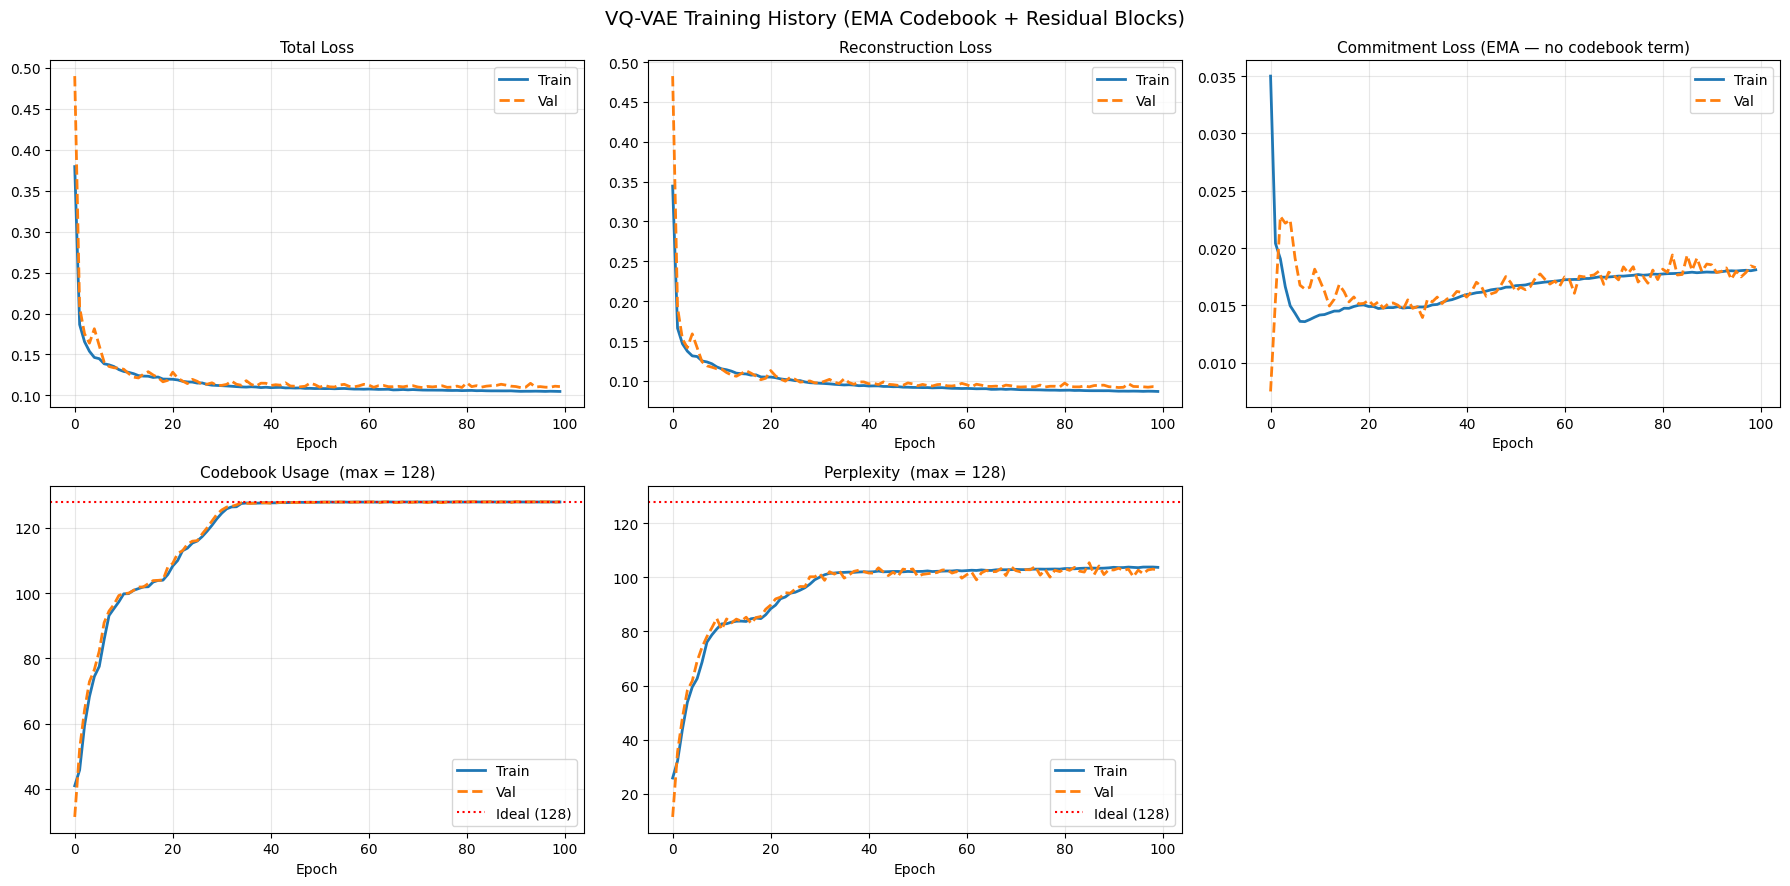

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.ravel()

plot_items = [
    ("total_loss",          "Total Loss"),
    ("reconstruction_loss", "Reconstruction Loss"),
    ("vq_loss",             "Commitment Loss (EMA — no codebook term)"),
    ("codebook_usage",      f"Codebook Usage  (max = {NUM_EMBEDDINGS})"),
    ("perplexity",          f"Perplexity  (max = {NUM_EMBEDDINGS})"),
]

for ax, (key, title) in zip(axes, plot_items):
    ax.plot(history.history[key],           label="Train", linewidth=2)
    ax.plot(history.history[f"val_{key}"],  label="Val",   linewidth=2, linestyle="--")
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(True, alpha=0.3)

# Show ideal ceiling on the two codebook metrics
for idx in [3, 4]:
    axes[idx].axhline(
        NUM_EMBEDDINGS, color="red", linestyle=":", linewidth=1.5,
        label=f"Ideal ({NUM_EMBEDDINGS})"
    )
    axes[idx].legend()

axes[5].set_visible(False)   # 6th subplot unused

plt.suptitle("VQ-VAE Training History (EMA Codebook + Residual Blocks)", fontsize=14)
plt.tight_layout()
plt.show()

## Reconstructions

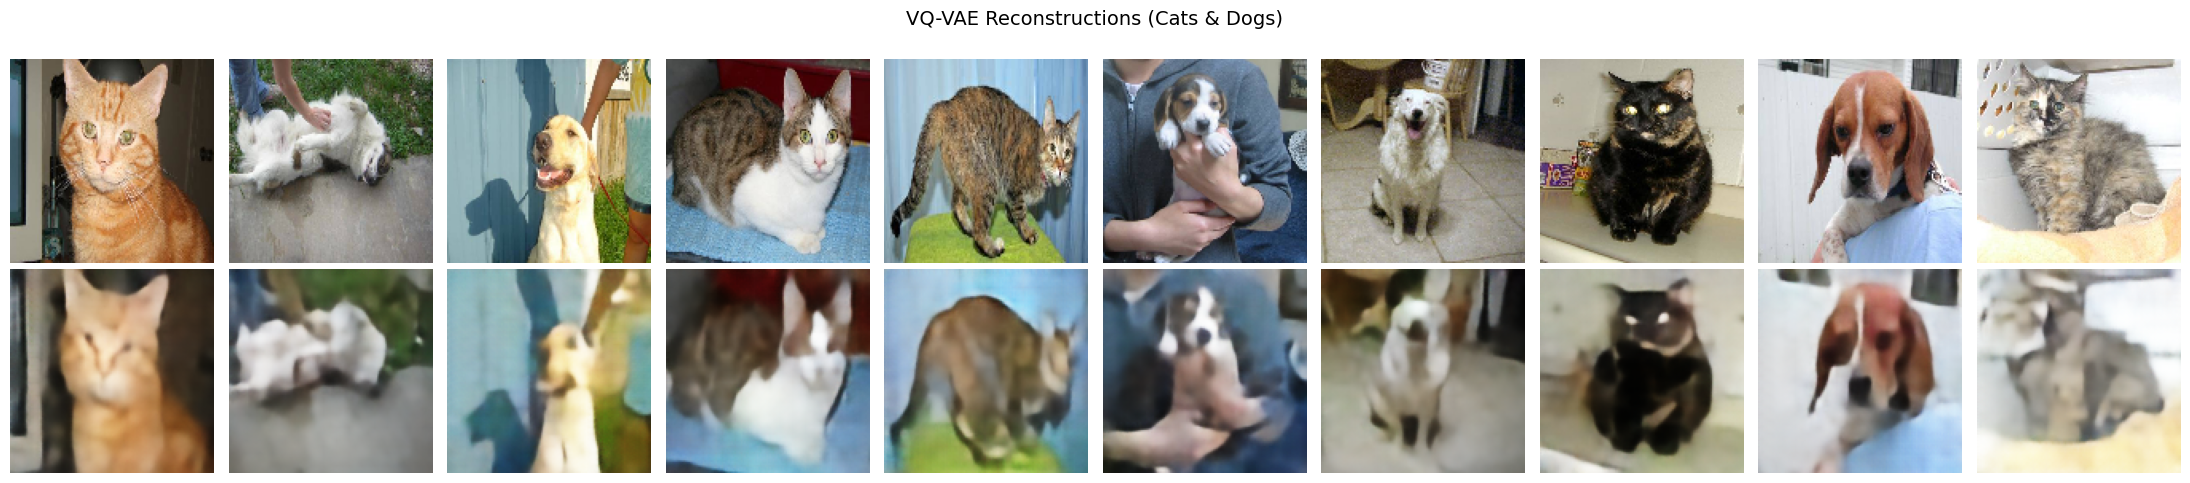

In [12]:
n   = 10
idx = np.random.choice(len(x_test), n, replace=False)
originals = x_test[idx]

# vqvae returns [reconstructions, indices]; take index 0
preds = trainer.vqvae.predict(originals, verbose=0)
reconstructions = np.clip(preds[0], 0, 1)

fig, axes = plt.subplots(2, n, figsize=(22, 5))
for i in range(n):
    axes[0, i].imshow(originals[i])
    axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i])
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original",      fontsize=11, labelpad=8)
axes[1, 0].set_ylabel("Reconstructed", fontsize=11, labelpad=8)
plt.suptitle("VQ-VAE Reconstructions (Cats & Dogs)", fontsize=14)
plt.tight_layout()
plt.show()

## Codebook Analysis

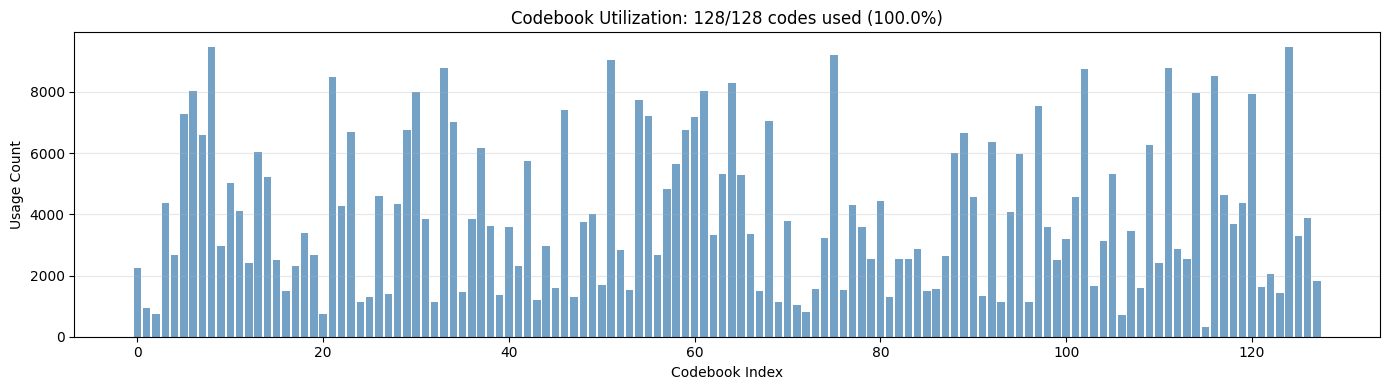

Codes used : 128 / 128 (100.0%)
Most used  : code 8  (9476 times)
Least used : code 115  (303 times)


In [13]:
# Encode entire test set and collect which codes are used
z_e_test = trainer.encoder.predict(x_test, verbose=0)   # (N, 16, 16, D)
emb_np   = trainer.vq_layer.embeddings.numpy()           # (D, K)

flat_z    = z_e_test.reshape(-1, EMBEDDING_DIM)
distances = (
    np.sum(flat_z ** 2, axis=1, keepdims=True)
    + np.sum(emb_np ** 2, axis=0, keepdims=True)
    - 2.0 * flat_z @ emb_np
)
all_indices = np.argmin(distances, axis=1)   # (N*H*W,)

unique_codes, counts = np.unique(all_indices, return_counts=True)
utilization = len(unique_codes) / NUM_EMBEDDINGS * 100

usage = np.zeros(NUM_EMBEDDINGS)
usage[unique_codes] = counts

plt.figure(figsize=(14, 4))
plt.bar(range(NUM_EMBEDDINGS), usage, color="steelblue", alpha=0.75)
plt.xlabel("Codebook Index")
plt.ylabel("Usage Count")
plt.title(
    f"Codebook Utilization: {len(unique_codes)}/{NUM_EMBEDDINGS} codes used "
    f"({utilization:.1f}%)"
)
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Codes used : {len(unique_codes)} / {NUM_EMBEDDINGS} ({utilization:.1f}%)")
print(f"Most used  : code {unique_codes[np.argmax(counts)]}  ({counts.max()} times)")
print(f"Least used : code {unique_codes[np.argmin(counts)]}  ({counts.min()} times)")

## Latent Code Maps

Each image is encoded into a 16×16 grid of discrete tokens. Visualising this grid shows which codebook entries cover which spatial regions.

C:\Users\ttejkiran\AppData\Local\Temp\ipykernel_16832\3752925312.py:33: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


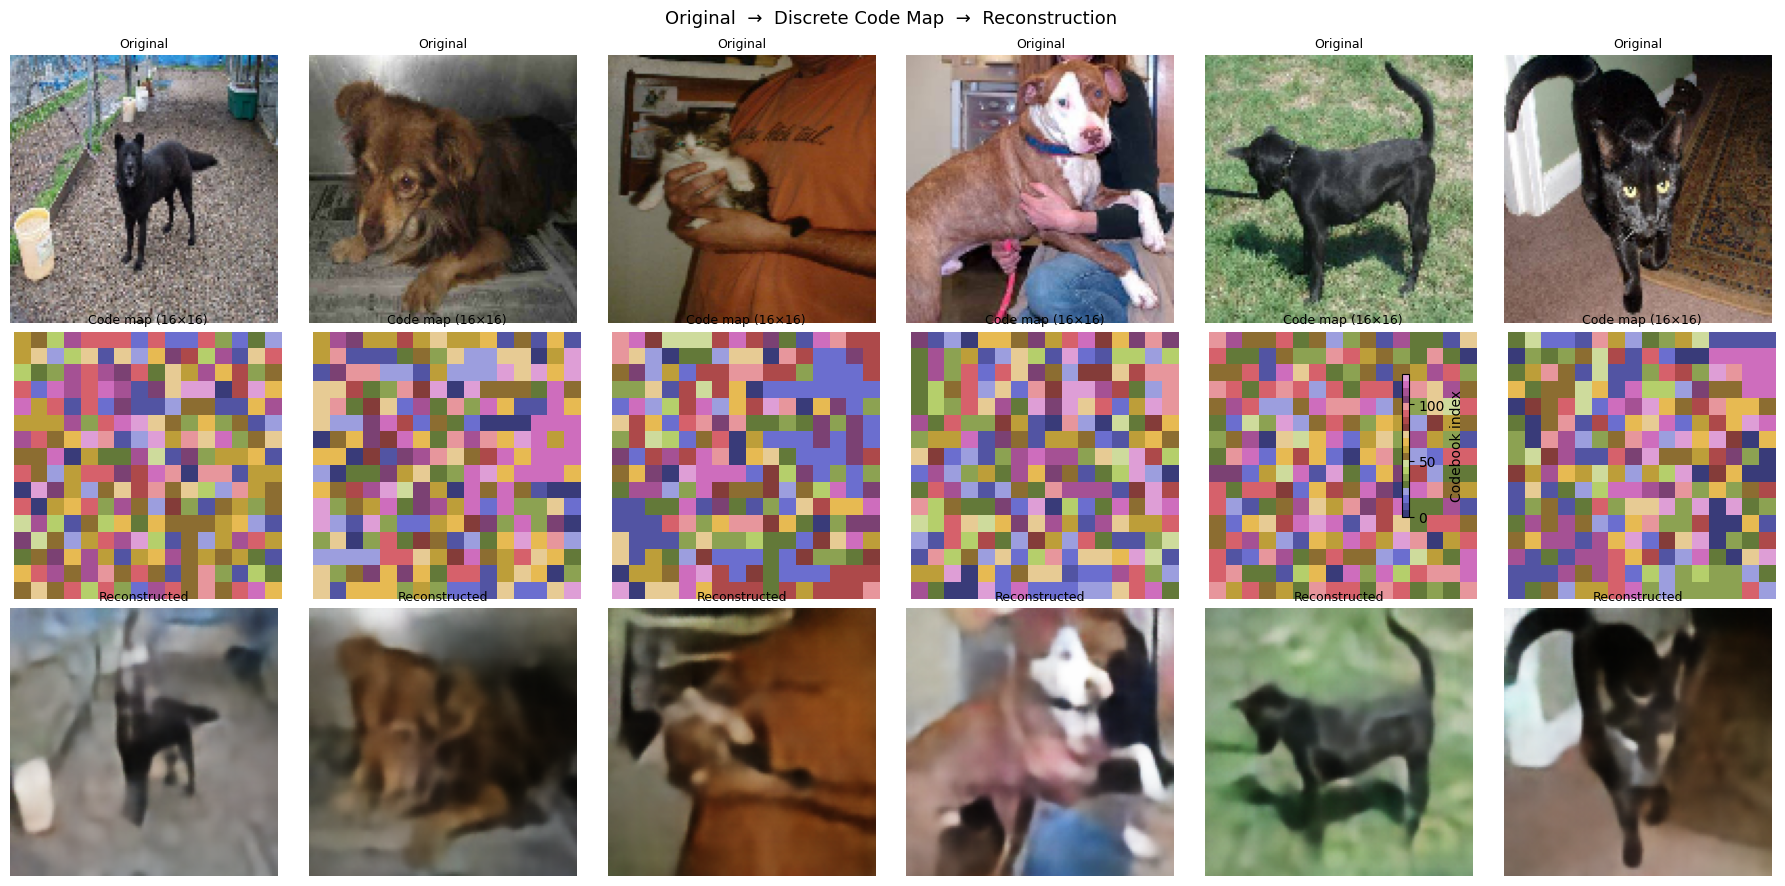

In [14]:
n   = 6
idx = np.random.choice(len(x_test), n, replace=False)
samples = x_test[idx]

z_e    = trainer.encoder.predict(samples, verbose=0)   # (n, 16, 16, D)
flat_z = z_e.reshape(-1, EMBEDDING_DIM)
dists  = (
    np.sum(flat_z ** 2, axis=1, keepdims=True)
    + np.sum(emb_np ** 2, axis=0, keepdims=True)
    - 2.0 * flat_z @ emb_np
)
code_maps = np.argmin(dists, axis=1).reshape(n, LATENT_H, LATENT_W)

preds  = trainer.vqvae.predict(samples, verbose=0)
recons = np.clip(preds[0], 0, 1)

fig, axes = plt.subplots(3, n, figsize=(18, 9))
for i in range(n):
    axes[0, i].imshow(samples[i])
    axes[0, i].set_title("Original", fontsize=9)
    axes[0, i].axis("off")

    im = axes[1, i].imshow(code_maps[i], cmap="tab20b", vmin=0, vmax=NUM_EMBEDDINGS - 1)
    axes[1, i].set_title(f"Code map ({LATENT_H}×{LATENT_W})", fontsize=9)
    axes[1, i].axis("off")

    axes[2, i].imshow(recons[i])
    axes[2, i].set_title("Reconstructed", fontsize=9)
    axes[2, i].axis("off")

plt.colorbar(im, ax=axes[1, :].tolist(), shrink=0.7, label="Codebook index")
plt.suptitle("Original  →  Discrete Code Map  →  Reconstruction", fontsize=13)
plt.tight_layout()
plt.show()

## Visualise Codebook Embeddings (PCA)

Project the 128 codebook vectors from D=64 dims down to 2D so we can see their distribution.

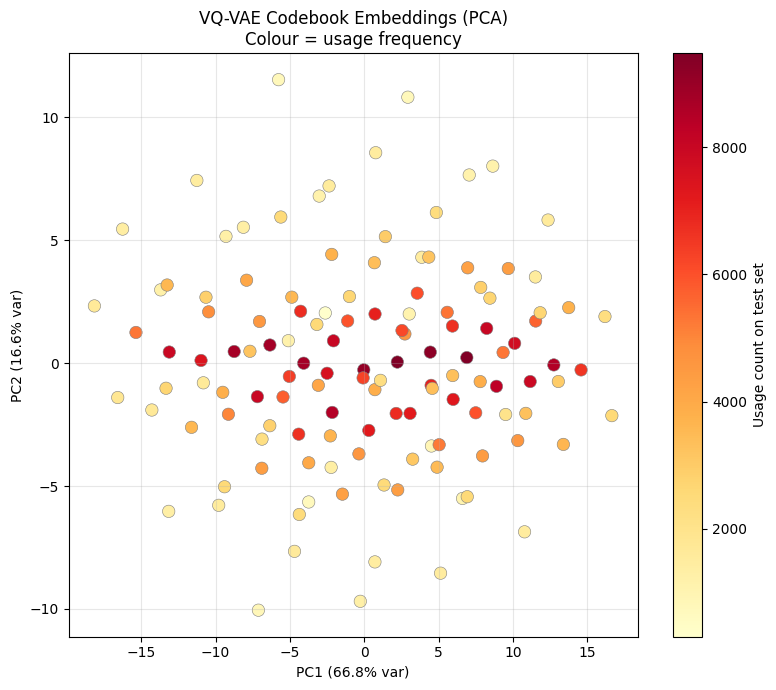

In [15]:
from sklearn.decomposition import PCA

emb = emb_np.T   # (K, D) — K codebook vectors

pca      = PCA(n_components=2)
emb_2d   = pca.fit_transform(emb)

plt.figure(figsize=(8, 7))
sc = plt.scatter(
    emb_2d[:, 0], emb_2d[:, 1],
    c=usage,
    cmap="YlOrRd",
    s=80,
    edgecolors="grey",
    linewidths=0.4,
)
plt.colorbar(sc, label="Usage count on test set")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")
plt.title("VQ-VAE Codebook Embeddings (PCA)\nColour = usage frequency")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Save Model Components

In [16]:
trainer.vqvae.save("vqvae_model.keras")
trainer.encoder.save("vqvae_encoder.keras")
trainer.decoder.save("vqvae_decoder.keras")
np.save("vqvae_codebook.npy", trainer.vq_layer.embeddings.numpy())

print("Saved:")
print("  vqvae_model.keras    — full functional model (encoder + VQ + decoder)")
print("  vqvae_encoder.keras")
print("  vqvae_decoder.keras")
print(f"  vqvae_codebook.npy  ({NUM_EMBEDDINGS}×{EMBEDDING_DIM})")

Saved:
  vqvae_model.keras    — full functional model (encoder + VQ + decoder)
  vqvae_encoder.keras
  vqvae_decoder.keras
  vqvae_codebook.npy  (128×64)


## Load & Test a Saved Model

Use these cells any time — including in a **fresh kernel** — to restore the trained model from disk and run inference without retraining.

**Fresh-kernel checklist** (run these cells first):
1. `imports-cell` — numpy, TF, Keras
2. `hyperparams` — IMAGE_SIZE, NUM_EMBEDDINGS, etc.
3. `vq-layer` — defines `VectorQuantizerEMA` (needed by `custom_objects`)
4. `encoder-decoder` — defines `residual_block` (needed to reconstruct the architecture)
5. The two cells below

In [29]:
# ── Restore saved model from disk ─────────────────────────────────────────
# VectorQuantizerEMA is a custom layer, so Keras needs it in custom_objects.
# The encoder / decoder sub-models have no custom layers, so no custom_objects needed.

SAVE_DIR = "."   # folder where the .keras / .npy files were saved

loaded_vqvae = keras.models.load_model(
    f"{SAVE_DIR}/vqvae_model.keras",
    custom_objects={"VectorQuantizerEMA": VectorQuantizerEMA},
)
loaded_encoder   = keras.models.load_model(f"{SAVE_DIR}/vqvae_encoder.keras")
loaded_decoder   = keras.models.load_model(f"{SAVE_DIR}/vqvae_decoder.keras")
loaded_codebook  = np.load(f"{SAVE_DIR}/vqvae_codebook.npy")  # shape: (D, K)

print("Restored:")
print(f"  vqvae    input  → {loaded_vqvae.input_shape}")
print(f"  vqvae    output → {[s.shape for s in loaded_vqvae.output]}")
print(f"  encoder  output → {loaded_encoder.output_shape}")
print(f"  decoder  output → {loaded_decoder.output_shape}")
print(f"  codebook shape  → {loaded_codebook.shape}  (D={loaded_codebook.shape[0]} × K={loaded_codebook.shape[1]})")

Restored:
  vqvae    input  → (None, 128, 128, 3)
  vqvae    output → [(None, 128, 128, 3), (None, 16, 16)]
  encoder  output → (None, 16, 16, 64)
  decoder  output → (None, 128, 128, 3)
  codebook shape  → (64, 128)  (D=64 × K=128)


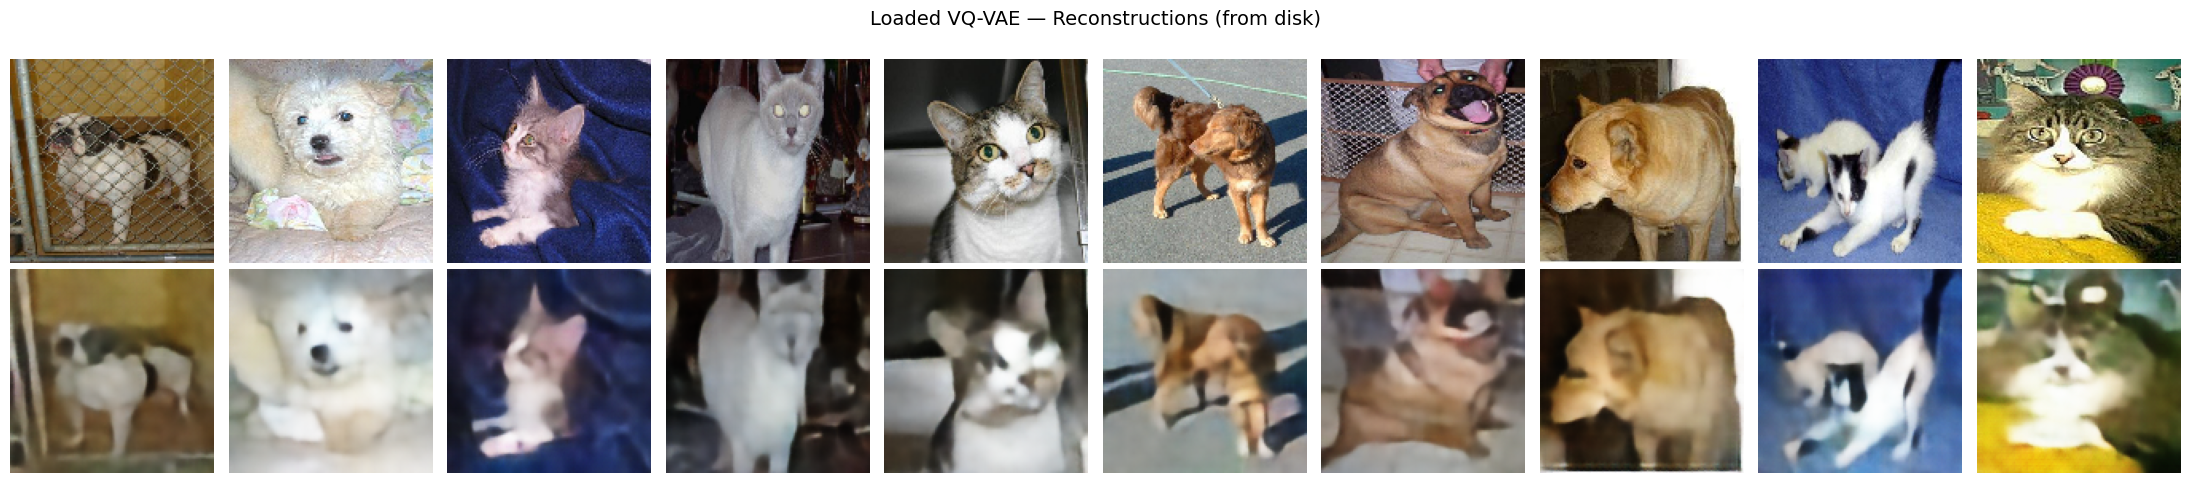

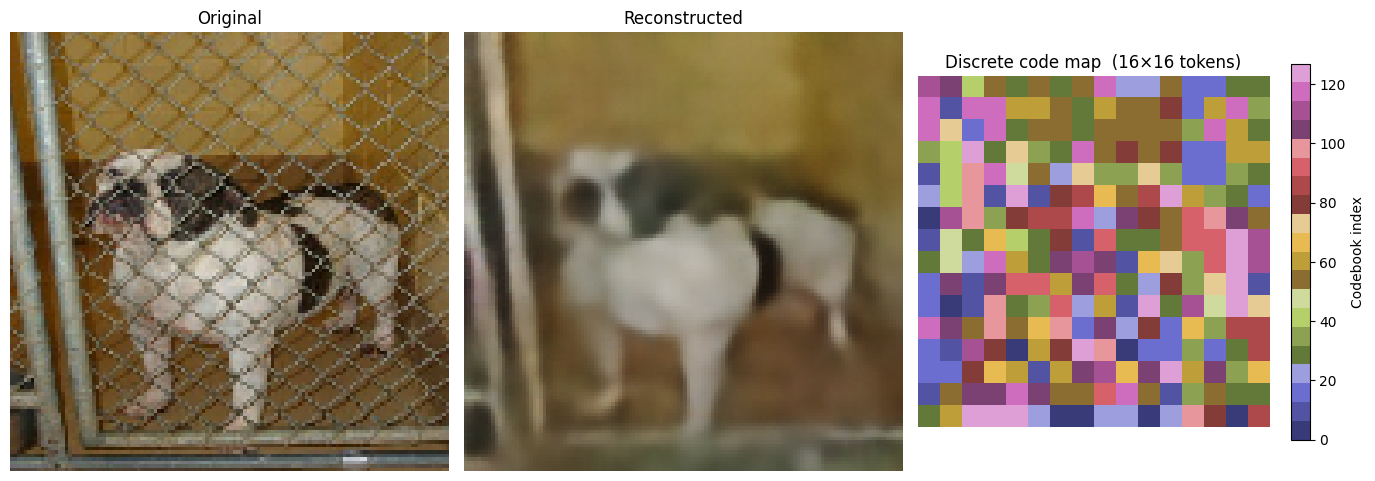

Codes used in batch : 127 / 128
Batch perplexity    : 100.4  (ideal = 128)
Most-used code      : #111  (68 assignments)


In [30]:
# ── Inference test ─────────────────────────────────────────────────────────
# Reconstruct a random batch from x_test and print codebook stats.
# x_test must be loaded (run data cells), or replace with your own images.

n   = 10
idx = np.random.choice(len(x_test), n, replace=False)
originals = x_test[idx]                              # (n, 128, 128, 3)

# Full forward pass — returns [reconstructions, code_indices]
preds           = loaded_vqvae.predict(originals, verbose=0)
reconstructions = np.clip(preds[0], 0, 1)            # (n, 128, 128, 3)
code_indices    = preds[1].astype(int)                # (n, 16, 16)

# --- Reconstruction grid ---
fig, axes = plt.subplots(2, n, figsize=(22, 5))
for i in range(n):
    axes[0, i].imshow(originals[i]);       axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i]); axes[1, i].axis("off")
axes[0, 0].set_ylabel("Original",      fontsize=11, labelpad=8)
axes[1, 0].set_ylabel("Reconstructed", fontsize=11, labelpad=8)
plt.suptitle("Loaded VQ-VAE — Reconstructions (from disk)", fontsize=14)
plt.tight_layout()
plt.show()

# --- Single image: original / reconstructed / code map ---
i = 0
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 5))
ax1.imshow(originals[i]);        ax1.set_title("Original");                ax1.axis("off")
ax2.imshow(reconstructions[i]);  ax2.set_title("Reconstructed");           ax2.axis("off")
im = ax3.imshow(code_indices[i], cmap="tab20b",
                vmin=0, vmax=NUM_EMBEDDINGS - 1)
ax3.set_title(f"Discrete code map  ({LATENT_H}×{LATENT_W} tokens)");      ax3.axis("off")
plt.colorbar(im, ax=ax3, shrink=0.8, label="Codebook index")
plt.tight_layout()
plt.show()

# --- Codebook statistics for this batch ---
flat            = code_indices.reshape(-1)
unique, counts  = np.unique(flat, return_counts=True)
probs           = counts / counts.sum()
perplexity      = float(np.exp(-np.sum(probs * np.log(probs + 1e-10))))

print(f"Codes used in batch : {len(unique)} / {NUM_EMBEDDINGS}")
print(f"Batch perplexity    : {perplexity:.1f}  (ideal = {NUM_EMBEDDINGS})")
print(f"Most-used code      : #{unique[counts.argmax()]}  ({counts.max()} assignments)")